# Assignment 3: Classical Machine Learning Threat Classification
**Course:** AI in Cyber Security Lab (`ENSP355`)  
**Student:** Yatharth Chopra (`2301420022`) | **Program:** B.Tech CSE (Data Science), Sem 7  
**University:** K.R. Mangalam University | **Faculty:** Monika Khatkar

---

### Objective
Train and evaluate three classical Machine Learning classifiers on the harmonised phishing dataset:
1. **Logistic Regression** (linear baseline)
2. **Decision Tree** (`max_depth=6`, interpretable rule-based model)
3. **Random Forest** (`n_estimators=200, max_depth=12`, ensemble bagging classifier)

All 9 categorical indicators (`-1, 0, 1`) are **one-hot encoded** inside a `scikit-learn` `Pipeline` fitted strictly on the **80% stratified training split** (`label x source`) to prevent data leakage.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from common import FEATURES, RANDOM_STATE, load_data
from preprocessing import build_preprocessor, split_data
from evaluation import fit_and_score, metrics_by_source

df = load_data()
X_train, X_test, y_train, y_test = split_data(df)
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows | Threat Share: {y_test.mean():.3f}")

Train: 9,926 rows | Test: 2,482 rows | Threat Share: 0.460


### 3.1 Train Models & Evaluate Confusion Matrices

=== Logistic Regression ===
              precision    recall  f1-score   support

  Legitimate      0.895     0.920     0.907      1341
      Threat      0.903     0.873     0.888      1141

    accuracy                          0.898      2482
   macro avg      0.899     0.897     0.898      2482
weighted avg      0.899     0.898     0.898      2482

=== Decision Tree ===
              precision    recall  f1-score   support

  Legitimate      0.904     0.923     0.913      1341
      Threat      0.907     0.884     0.896      1141

    accuracy                          0.905      2482
   macro avg      0.906     0.904     0.905      2482
weighted avg      0.905     0.905     0.905      2482



=== Random Forest ===
              precision    recall  f1-score   support

  Legitimate      0.920     0.944     0.932      1341
      Threat      0.932     0.904     0.918      1141

    accuracy                          0.925      2482
   macro avg      0.926     0.924     0.925      2482
weighted avg      0.926     0.925     0.925      2482



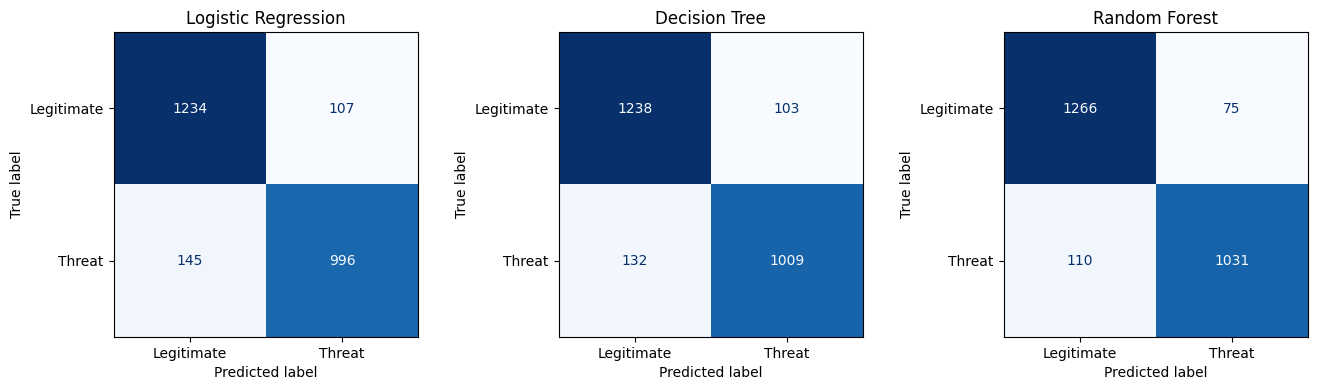

In [2]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1),
}

results, by_source, fitted = [], [], {}
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4))
for ax, (name, clf) in zip(axes, models.items()):
    pipe = Pipeline([("prep", build_preprocessor()), ("clf", clf)])
    res, pred = fit_and_score(pipe, X_train, X_test, y_train, y_test)
    results.append({"model": name, **res})
    by_source += [{"model": name, **r} for r in metrics_by_source(X_test, y_test, pred)]
    fitted[name] = pipe
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["Legitimate", "Threat"], digits=3))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Legitimate", "Threat"], cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 3.2 Overall & Per-Source Performance Summary

In [3]:
res_df = pd.DataFrame(results).round(4)
display(res_df)

print("\nPer-Source Breakdown:")
display(pd.DataFrame(by_source).round(4))

,model,accuracy,precision,recall,f1,roc_auc,train_time_s,predict_time_ms,acc_seen_profiles,acc_unseen_profiles,share_unseen_profiles
0,Logistic Regression,0.8985,0.9030,0.8729,0.8877,0.9643,0.0218,4.8034,0.9076,0.7213,0.0492
1,Decision Tree,0.9053,0.9074,0.8843,0.8957,0.9705,0.0206,4.5064,0.9089,0.8361,0.0492
2,Random Forest,0.9255,0.9322,0.9036,0.9177,0.9797,0.2952,41.1462,0.9292,0.8525,0.0492



Per-Source Breakdown:


,model,source,test_rows,accuracy,precision,recall,f1
0,Logistic Regression,Dataset A (UCI 327),2211,0.9100,0.9176,0.8755,0.8961
1,Logistic Regression,Dataset B (UCI 379),271,0.8044,0.8214,0.8571,0.8389
2,Decision Tree,Dataset A (UCI 327),2211,0.9077,0.9076,0.8816,0.8944
3,Decision Tree,Dataset B (UCI 379),271,0.8856,0.9062,0.9006,0.9034
4,Random Forest,Dataset A (UCI 327),2211,0.9317,0.9368,0.9071,0.9217
5,Random Forest,Dataset B (UCI 379),271,0.8745,0.9045,0.8820,0.8931


### 3.3 Feature Importance Comparison

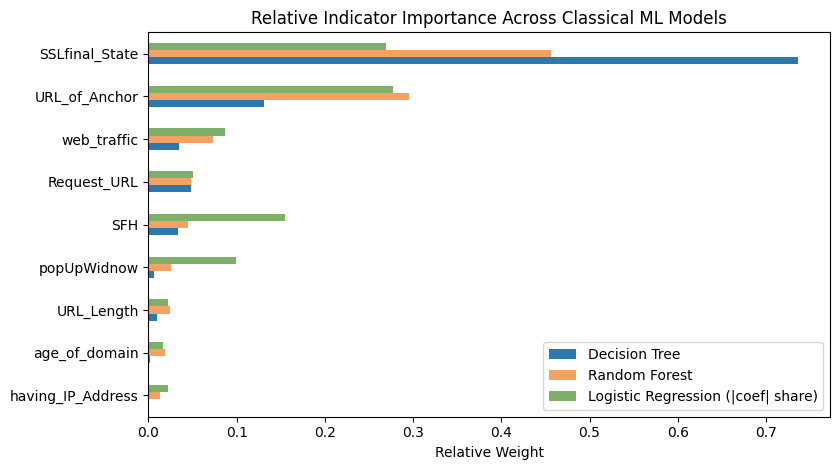

,Decision Tree,Random Forest,Logistic Regression (|coef| share)
SSLfinal_State,0.7358,0.4567,0.2697
URL_of_Anchor,0.1309,0.2958,0.2776
web_traffic,0.0347,0.0729,0.0867
Request_URL,0.0486,0.0487,0.0510
SFH,0.0332,0.0454,0.1543
popUpWidnow,0.0063,0.0254,0.0995
URL_Length,0.0092,0.0239,0.0221
age_of_domain,0.0012,0.0184,0.0170
having_IP_Address,0.0000,0.0129,0.0222


In [4]:
names = fitted["Decision Tree"].named_steps["prep"].get_feature_names_out()
def agg_feat(vals):
    s = pd.Series(vals, index=names)
    return s.groupby(lambda n: next(f for f in FEATURES if f in n)).sum()

lr_w = agg_feat(np.abs(fitted["Logistic Regression"].named_steps["clf"].coef_[0]))
imp = pd.DataFrame({
    "Decision Tree": agg_feat(fitted["Decision Tree"].named_steps["clf"].feature_importances_),
    "Random Forest": agg_feat(fitted["Random Forest"].named_steps["clf"].feature_importances_),
    "Logistic Regression (|coef| share)": lr_w / lr_w.sum(),
}).sort_values("Random Forest")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
imp.plot.barh(ax=ax, color=["#2a7ab0", "#f4a261", "#7fb069"])
ax.set_title("Relative Indicator Importance Across Classical ML Models")
ax.set_xlabel("Relative Weight")
plt.tight_layout()
plt.show()
display(imp.iloc[::-1].round(4))